<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%9C%D0%9D_%D0%9B%D0%9113.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Імпорти

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

!pip -q install kagglehub
import kagglehub

Завантаження даних

In [2]:
path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
/kaggle/input/cards-image-datasetclassification
['53cards-53-(200 X 200)-100.00.h5', 'cards.csv', 'valid', 'test', '14card types-14-(200 X 200)-94.61.h5', 'train']


In [3]:
IMG_SIZE = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(path, "train"), image_size=IMG_SIZE, batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(path, "valid"), image_size=IMG_SIZE, batch_size=BATCH)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(path, "test"), image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Кількість класів:", num_classes)
print(class_names)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Кількість класів: 53
['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades', 'four of clubs', 'four of diamonds', 'four of hearts', 'four of spades', 'jack of clubs', 'jack of diamonds', 'jack of hearts', 'jack of spades', 'joker', 'king of clubs', 'king of diamonds', 'king of hearts', 'king of spades', 'nine of clubs', 'nine of diamonds', 'nine of hearts', 'nine of spades', 'queen of clubs', 'queen of diamonds', 'queen of hearts', 'queen of spades', 'seven of clubs', 'seven of diamonds', 'seven of hearts', 'seven of spades', 'six of clubs', 'six of diamonds', 'six of hearts', 'six of spades', 'ten of clubs', 'ten of diamonds', 'ten of hearts', 'ten of spades', 'three of clubs', 'three of diamonds', 'th

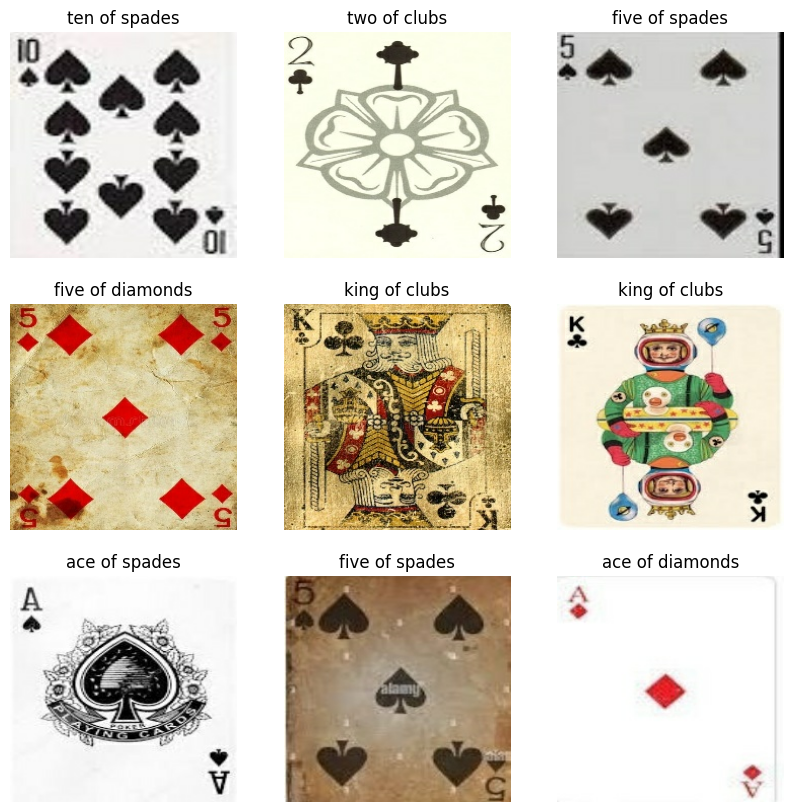

In [4]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

Виконання

train: всього 7624, мін/клас 108, макс/клас 181
valid: всього 265, мін/клас 5, макс/клас 5
test: всього 265, мін/клас 5, макс/клас 5


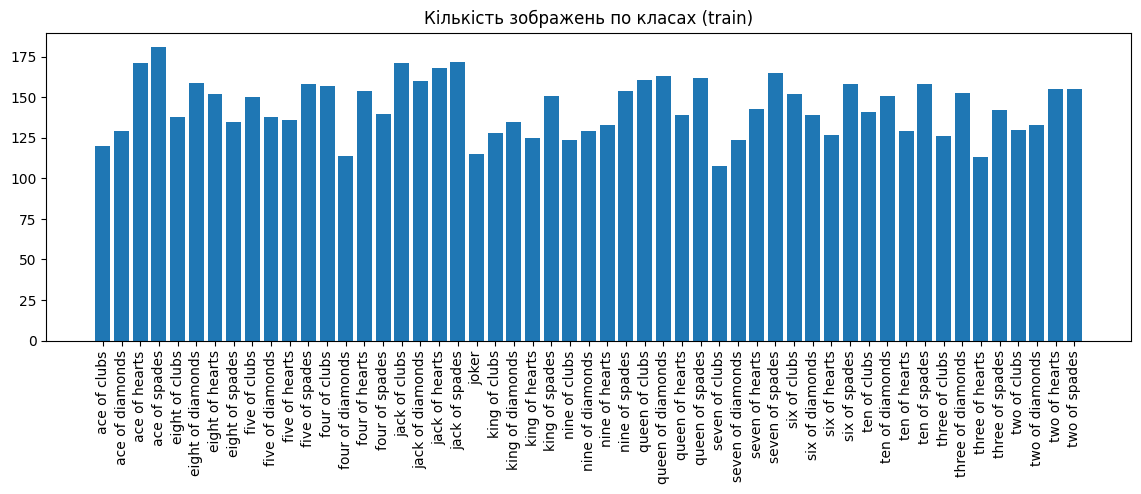

Розмір батчу: (32, 224, 224, 3) | діапазон пікселів: 0.0 - 255.0


In [5]:
for split in ["train", "valid", "test"]:
    folder = os.path.join(path, split)
    counts = [len(os.listdir(os.path.join(folder, c))) for c in class_names]
    print(f"{split}: всього {sum(counts)}, мін/клас {min(counts)}, макс/клас {max(counts)}")

train_counts = [len(os.listdir(os.path.join(path, "train", c))) for c in class_names]
plt.figure(figsize=(14, 4))
plt.bar(class_names, train_counts)
plt.xticks(rotation=90)
plt.title("Кількість зображень по класах (train)")
plt.show()

print("Розмір батчу:", images.shape, "| діапазон пікселів:", images.numpy().min(), "-", images.numpy().max())

In [6]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


augmentation = models.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

def plot_history(histories, title):
    acc = sum([h.history["accuracy"] for h in histories], [])
    val_acc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"] for h in histories], [])
    val_loss = sum([h.history["val_loss"] for h in histories], [])
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc, label="train"); plt.plot(val_acc, label="val")
    plt.title(title + " - accuracy"); plt.xlabel("epoch"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(loss, label="train"); plt.plot(val_loss, label="val")
    plt.title(title + " - loss"); plt.xlabel("epoch"); plt.legend()
    plt.show()

def early_stop():
    return EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

In [7]:
def build_cnn(lr=1e-3, dropout=0.3):
    model = models.Sequential([
        layers.Input((224, 224, 3)),
        layers.Rescaling(1./255),
        augmentation,
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

build_cnn().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 53)             │         6,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,181 (1.01 MB)

 Trainable params: 264,181 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
best_acc, best_params = 0, None
for lr in [1e-3, 3e-4]:
    for dropout in [0.3, 0.5]:
        model = build_cnn(lr, dropout)
        h = model.fit(train_ds, validation_data=val_ds, epochs=8,
                      callbacks=[early_stop()], verbose=0)
        acc = max(h.history["val_accuracy"])
        print(f"lr={lr}, dropout={dropout} -> val_acc={acc:.3f}")
        if acc > best_acc:
            best_acc, best_params = acc, (lr, dropout)

print("Найкращі параметри CNN:", best_params, best_acc)

lr=0.001, dropout=0.3 -> val_acc=0.291
lr=0.001, dropout=0.5 -> val_acc=0.272
lr=0.0003, dropout=0.3 -> val_acc=0.147
lr=0.0003, dropout=0.5 -> val_acc=0.117
Найкращі параметри CNN: (0.001, 0.3) 0.29056602716445923


Epoch 1/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.0317 - loss: 3.8234 - val_accuracy: 0.0377 - val_loss: 3.6654
Epoch 2/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 20s 52ms/step - accuracy: 0.0681 - loss: 3.3859 - val_accuracy: 0.1208 - val_loss: 2.9913
Epoch 3/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.1031 - loss: 3.1563 - val_accuracy: 0.1094 - val_loss: 2.9318
Epoch 4/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.1131 - loss: 3.0376 - val_accuracy: 0.1321 - val_loss: 2.9520
Epoch 5/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.1313 - loss: 2.9487 - val_accuracy: 0.1547 - val_loss: 2.7819
Epoch 6/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.1527 - loss: 2.8423 - val_accuracy: 0.1396 - val_loss: 2.7850
Epoch 7/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.1693 - loss: 2.7412 - val_accuracy: 0.1660 - val_loss: 2.8048
Epoch 8/40
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.1866 - loss: 2.6497 - 

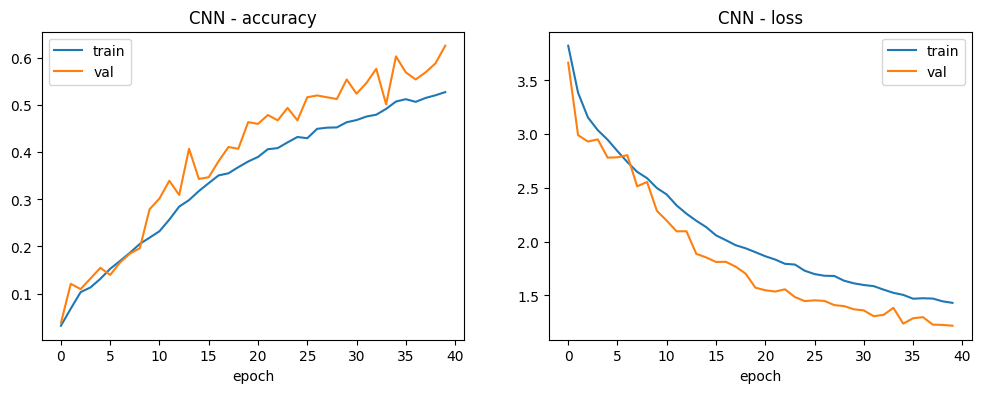

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5660 - loss: 1.4782 
CNN test accuracy: 0.5660377144813538


In [9]:
cnn = build_cnn(*best_params)
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=40,
                callbacks=[early_stop()])
plot_history([h_cnn], "CNN")
cnn_loss, cnn_acc = cnn.evaluate(test_ds)
print("CNN test accuracy:", cnn_acc)

In [10]:
def build_vgg(lr=1e-3, dropout=0.3):
    base = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base.trainable = False
    inputs = layers.Input((224, 224, 3))
    x = augmentation(inputs)
    x = preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base

In [11]:
best_acc, best_params_vgg = 0, None
for lr in [1e-3, 1e-4]:
    for dropout in [0.3, 0.5]:
        model, _ = build_vgg(lr, dropout)
        h = model.fit(train_ds, validation_data=val_ds, epochs=5,
                      callbacks=[early_stop()], verbose=0)
        acc = max(h.history["val_accuracy"])
        print(f"lr={lr}, dropout={dropout} -> val_acc={acc:.3f}")
        if acc > best_acc:
            best_acc, best_params_vgg = acc, (lr, dropout)

print("Найкращі параметри VGG16:", best_params_vgg, best_acc)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
lr=0.001, dropout=0.3 -> val_acc=0.426
lr=0.001, dropout=0.5 -> val_acc=0.392
lr=0.0001, dropout=0.3 -> val_acc=0.192
lr=0.0001, dropout=0.5 -> val_acc=0.181
Найкращі параметри VGG16: (0.001, 0.3) 0.4264150857925415


Epoch 1/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 45s 180ms/step - accuracy: 0.1373 - loss: 3.6139 - val_accuracy: 0.2755 - val_loss: 2.5094
Epoch 2/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 40s 169ms/step - accuracy: 0.2831 - loss: 2.4744 - val_accuracy: 0.3509 - val_loss: 2.0965
Epoch 3/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 42s 174ms/step - accuracy: 0.3595 - loss: 2.1206 - val_accuracy: 0.4189 - val_loss: 1.9654
Epoch 4/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 171ms/step - accuracy: 0.4164 - loss: 1.9093 - val_accuracy: 0.4189 - val_loss: 1.8386
Epoch 5/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 173ms/step - accuracy: 0.4559 - loss: 1.7678 - val_accuracy: 0.4226 - val_loss: 1.8908
Epoch 6/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 173ms/step - accuracy: 0.4890 - loss: 1.6356 - val_accuracy: 0.4528 - val_loss: 1.7493
Epoch 7/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 42s 174ms/step - accuracy: 0.5205 - loss: 1.5453 - val_accuracy: 0.4755 - val_loss: 1.7135
Epoch 8/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 173ms/step - accuracy: 0.5463 - loss: 1

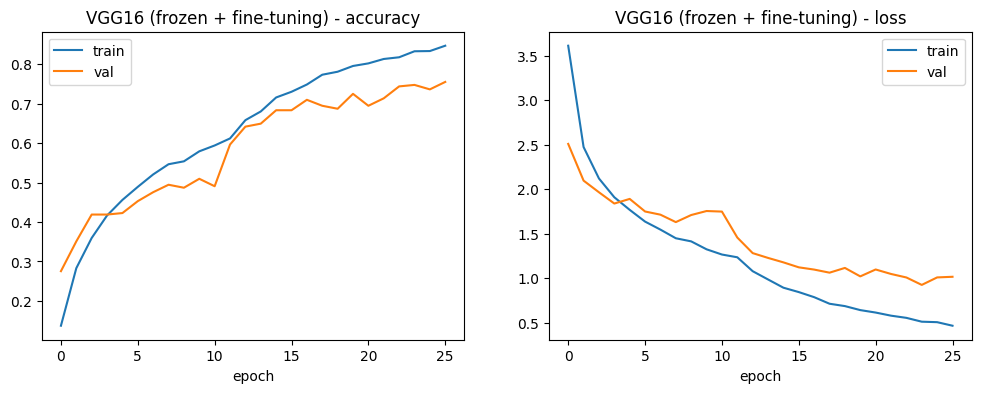

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - accuracy: 0.7057 - loss: 1.5340
VGG16 test accuracy: 0.7056604027748108


In [12]:
vgg, base = build_vgg(*best_params_vgg)

h1 = vgg.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early_stop()])

base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("block5")

vgg.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = vgg.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early_stop()])

plot_history([h1, h2], "VGG16 (frozen + fine-tuning)")
vgg_loss, vgg_acc = vgg.evaluate(test_ds)
print("VGG16 test accuracy:", vgg_acc)

In [13]:
print(f"CNN test accuracy: {cnn_acc:.4f}")
print(f"VGG16 test accuracy: {vgg_acc:.4f}")

CNN test accuracy: 0.5660
VGG16 test accuracy: 0.7057


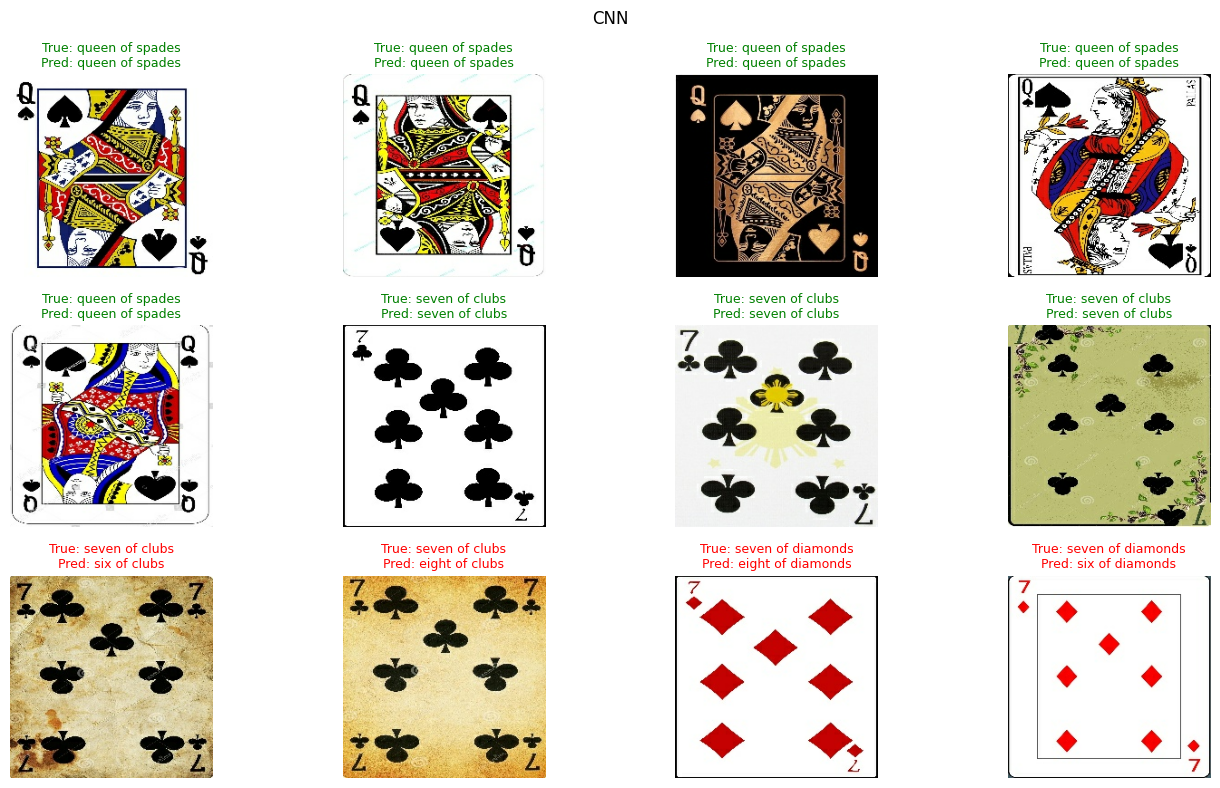

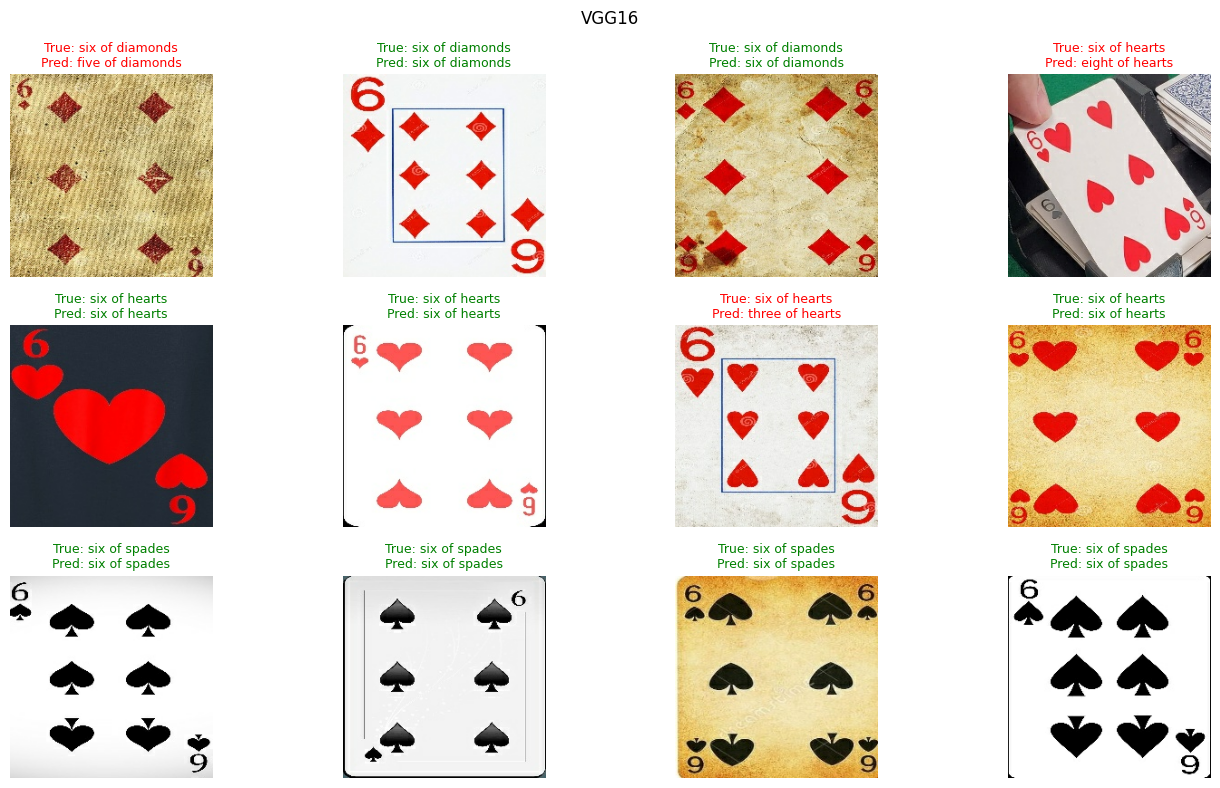

In [14]:
def show_predictions(model, name):
    images, labels = next(iter(test_ds.shuffle(10)))
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    plt.figure(figsize=(14, 8))
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true, pred = class_names[labels[i]], class_names[preds[i]]
        plt.title(f"True: {true}\nPred: {pred}", color="green" if true == pred else "red", fontsize=9)
        plt.axis("off")
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

show_predictions(cnn, "CNN")
show_predictions(vgg, "VGG16")

Висновок: CNN дала точність близько 57 відсотків, тоді як VGG16 показала кращий результат 70% точності на тесті. Перенавчання у CNN немає, навіть більше модель недонавчана(Однак, в колабі навіть навчання 40 епох дуже довго) бо loss все ще падаав. Судячи з візуалізації, моделі плутають схожі картки на кшталт 6/7 clubs